# 04 — Exploratory Data Analysis (EDA)

Notebook ini merangkum performa, risiko, korelasi, dan simulasi Rp700.000 dari data nyata
proyek. Semua angka berasal dari dataset lokal; tetap bukan rekomendasi investasi.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if (ROOT / "notebooks").exists():
    pass
elif ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
print("Root proyek:", ROOT)

Root proyek: C:\Users\53\Documents\data sains\project saham


In [2]:
from src.data_loader import load_historical_prices
from src.data_cleaning import clean_historical
from src.stock_analysis import performance_table, prepare_comparison, returns_matrix
from src.risk_analysis import risk_table

prices = clean_historical(load_historical_prices())
stocks = sorted(t for t in prices["ticker"].unique() if not t.startswith("^"))
print("Saham:", len(stocks), stocks)

Saham: 12 ['ADRO.JK', 'AKRA.JK', 'ANTM.JK', 'ASII.JK', 'BBCA.JK', 'BBRI.JK', 'BMRI.JK', 'GOTO.JK', 'ICBP.JK', 'SMGR.JK', 'TLKM.JK', 'UNVR.JK']


## 1. Performa dan risiko sejak awal data

In [3]:
start = prices["date"].min()
end = prices["date"].max()
perf = performance_table(prices, stocks + ["^JKSE"], start=start, end=end)
perf["Total Return (%)"] = perf["Total Return"] * 100
perf["CAGR (%)"] = perf["CAGR"] * 100
perf["Volatilitas (%)"] = perf["Volatilitas Tahunan"] * 100
perf["Max Drawdown (%)"] = perf["Max Drawdown"] * 100
perf[["Ticker", "Observasi", "Total Return (%)", "CAGR (%)", "Volatilitas (%)", "Max Drawdown (%)"]].sort_values("Total Return (%)", ascending=False)

,Ticker,Observasi,Total Return (%),CAGR (%),Volatilitas (%),Max Drawdown (%)
0,ADRO.JK,1898,669.515376,29.830532,45.293443,-59.242013
2,ANTM.JK,1899,379.207086,22.197321,50.718733,-70.256415
1,AKRA.JK,1899,162.487123,13.140458,42.230443,-72.943039
6,BMRI.JK,1899,70.843992,7.092063,33.944312,-52.050728
5,BBRI.JK,1899,35.475553,3.960755,33.114931,-52.433516
4,BBCA.JK,1899,16.954557,2.023841,26.938351,-51.792053
10,TLKM.JK,1898,-7.661482,-1.014561,33.075232,-51.926196
3,ASII.JK,1898,-9.215463,-1.229258,33.235074,-60.123749
12,^JKSE,1886,-13.073252,-1.777053,18.350418,-45.300790
8,ICBP.JK,1898,-31.145684,-4.662014,28.094773,-51.995483


In [4]:
risk, skipped = risk_table(prices, stocks, start=start, end=end, min_observations=60)
risk["Volatilitas (%)"] = risk["Volatilitas Tahunan"] * 100
risk["Max Drawdown (%)"] = risk["Max Drawdown"] * 100
risk["VaR 95% Harian (%)"] = risk["VaR 95% Harian"] * 100
risk[["Ticker", "Volatilitas (%)", "Max Drawdown (%)", "VaR 95% Harian (%)", "Hari Negatif"]].sort_values("Volatilitas (%)")

,Ticker,Volatilitas (%),Max Drawdown (%),VaR 95% Harian (%),Hari Negatif
4,BBCA.JK,26.938351,-51.792053,2.339862,0.465753
8,ICBP.JK,28.094773,-51.995483,2.702697,0.452820
10,TLKM.JK,33.075232,-51.926196,2.825440,0.471270
5,BBRI.JK,33.114931,-52.433516,2.983948,0.460485
3,ASII.JK,33.235074,-60.123749,3.012249,0.466526
6,BMRI.JK,33.944312,-52.050728,3.133243,0.449947
11,UNVR.JK,38.173866,-87.630083,3.362097,0.503688
1,AKRA.JK,42.230443,-72.943039,3.973009,0.470495
9,SMGR.JK,43.808170,-89.310802,4.091814,0.497366
0,ADRO.JK,45.293443,-59.242013,3.987255,0.457565


**Peringatan:** periode yang berbeda bisa mengubah peringkat. GOTO baru tercatat
pada 2022, jadi perbandingan harus dimulai pada tanggal yang sama.

## 2. Perbandingan harga ternormalisasi (awal = 100)

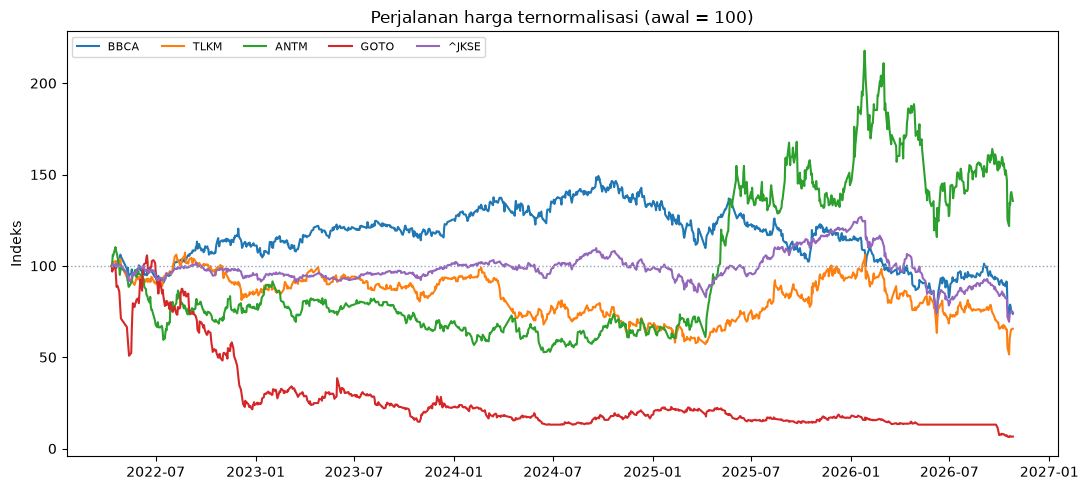

,BBCA.JK,TLKM.JK,ANTM.JK,GOTO.JK,^JKSE
date,,,,,
2026-10-22,77.289083,64.097380,139.450492,6.544503,74.792600
2026-10-23,75.048820,65.262787,140.432538,6.544503,75.505461
2026-10-26,73.779337,65.554138,135.522309,6.544503,74.587006


In [5]:
selected = ["BBCA.JK", "TLKM.JK", "ANTM.JK", "GOTO.JK", "^JKSE"]
comparison = prepare_comparison(prices, selected, start=start, end=end)

fig, ax = plt.subplots(figsize=(11, 5))
for column in comparison.columns:
    ax.plot(comparison.index, comparison[column], label=column.replace(".JK", ""), linewidth=1.5)
ax.axhline(100, color="#94A3B8", linestyle=":", linewidth=1)
ax.set_title("Perjalanan harga ternormalisasi (awal = 100)")
ax.set_ylabel("Indeks")
ax.legend(ncol=5, fontsize=8)
plt.tight_layout()
plt.show()

comparison.tail(3)

In [6]:
print("Periode efektif:", comparison.index.min().date(), "s/d", comparison.index.max().date())
for column in comparison.columns:
    total = comparison[column].iloc[-1] / 100 - 1
    print(f"{column:10s}: {total:+.1%}")

Periode efektif: 2022-04-11 s/d 2026-10-26
BBCA.JK   : -26.2%
TLKM.JK   : -34.4%
ANTM.JK   : +35.5%
GOTO.JK   : -93.5%
^JKSE     : -25.4%


## 3. Drawdown

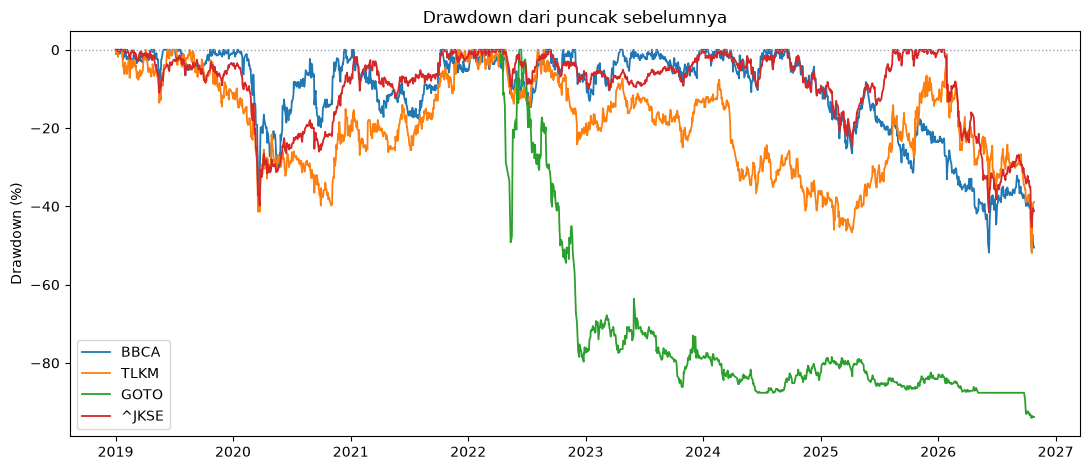

In [7]:
from src.stock_analysis import drawdown_series

fig, ax = plt.subplots(figsize=(11, 4.8))
for column in ["BBCA.JK", "TLKM.JK", "GOTO.JK", "^JKSE"]:
    series = prices[prices["ticker"] == column].set_index("date")["adj_close"].sort_index()
    dd = drawdown_series(series)
    ax.plot(dd.index, dd * 100, label=column.replace(".JK", ""), linewidth=1.3)
ax.axhline(0, color="#94A3B8", linestyle=":", linewidth=1)
ax.set_title("Drawdown dari puncak sebelumnya")
ax.set_ylabel("Drawdown (%)")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Korelasi return harian

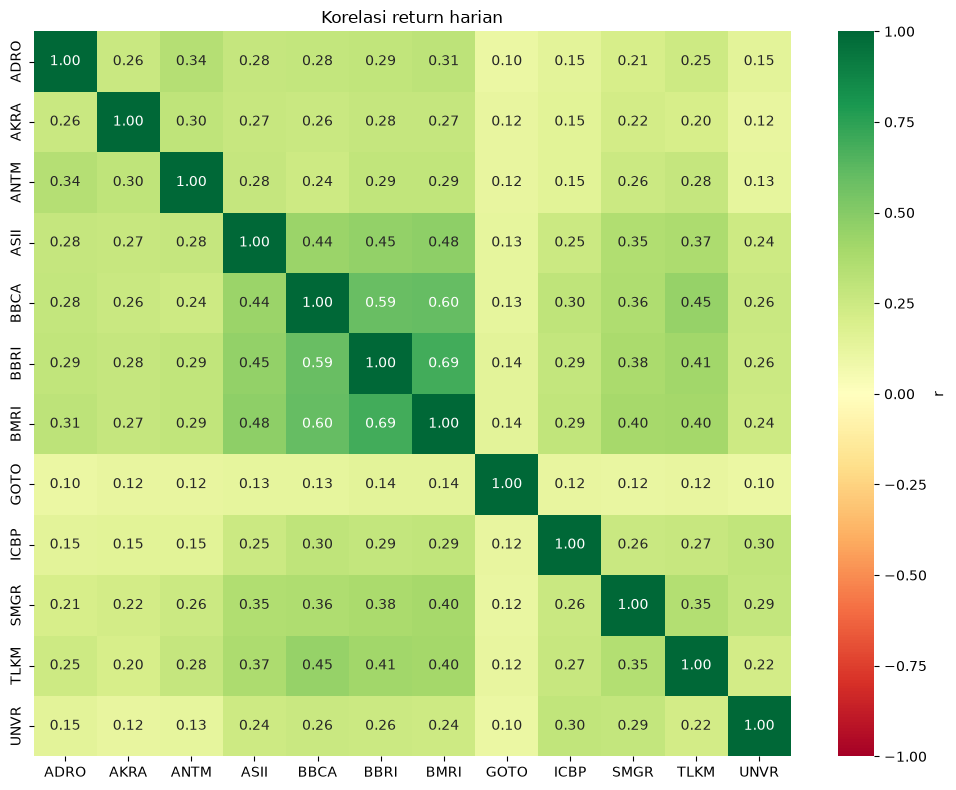

In [8]:
import seaborn as sns
from src.stock_analysis import correlation_matrix

returns = returns_matrix(prices, stocks, start=start, end=end)
corr = correlation_matrix(returns, min_periods=30)
corr.index = [t.replace(".JK", "") for t in corr.index]
corr.columns = [t.replace(".JK", "") for t in corr.columns]

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlGn", vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "r"})
ax.set_title("Korelasi return harian")
plt.tight_layout()
plt.show()

Korelasi tinggi berarti return cenderung bergerak searah, bukan berarti penyebabnya sama.
Korelasi juga tidak stabil sepanjang waktu.

## 5. Riset saham dan simulasi modal Rp700.000

In [9]:
from src.data_loader import load_snapshot, load_tickers
from src.data_cleaning import clean_snapshot
from src.screening import build_research_table

snapshot = clean_snapshot(load_snapshot())
tickers = load_tickers()
research = build_research_table(prices, tickers, snapshot=snapshot, start=start, end=end, min_observations=60)
research["Return (%)"] = research["Return Periode"] * 100
research["Volatilitas (%)"] = research["Volatilitas Tahunan"] * 100
research["Max Drawdown (%)"] = research["Max Drawdown"] * 100
research[["Ticker", "Sektor", "Harga Terakhir", "Return (%)", "Volatilitas (%)", "Max Drawdown (%)", "Nilai Transaksi 20H"]].sort_values("Return (%)", ascending=False)

,Ticker,Sektor,Harga Terakhir,Return (%),Volatilitas (%),Max Drawdown (%),Nilai Transaksi 20H
0,ADRO,Energi,2450.0,669.515376,45.293443,-59.242013,1.079910e+11
2,ANTM,Barang Baku,2760.0,379.207086,50.718733,-70.256415,2.605630e+11
1,AKRA,Energi,1400.0,162.487123,42.230443,-72.943039,3.331846e+10
6,BMRI,Keuangan,3910.0,70.843992,33.944312,-52.050728,8.093373e+11
5,BBRI,Keuangan,2910.0,35.475553,33.114931,-52.433516,9.405508e+11
4,BBCA,Keuangan,4940.0,16.954557,26.938351,-51.792053,1.628900e+12
10,TLKM,Telekomunikasi,2250.0,-7.661482,33.075232,-51.926196,6.511813e+11
3,ASII,Industri,4560.0,-9.215463,33.235074,-60.123749,2.782557e+11
8,ICBP,Konsumen Primer,5975.0,-31.145684,28.094773,-51.995483,4.528150e+10
11,UNVR,Konsumen Primer,1425.0,-78.094948,38.173866,-87.630083,3.153884e+10


In [10]:
from src.simulation import simulate_trade

result = simulate_trade(
    modal=700_000,
    allocation=280_000,
    price=2_500,
    lots=1,
    change_pct=5,
    buy_fee_pct=0.15,
    sell_fee_pct=0.15,
    tax_pct=0.10,
)
print(f"Total beli      : Rp{result.total_buy:,.0f}")
print(f"Hasil jual bersih: Rp{result.net_proceeds:,.0f}")
print(f"Laba/rugi bersih : Rp{result.net_profit:,.0f}")
print(f"Return investasi : {result.return_on_investment_pct:.2f}%")
print(f"Return modal     : {result.return_on_total_capital_pct:.2f}%")

Total beli      : Rp250,375
Hasil jual bersih: Rp261,844
Laba/rugi bersih : Rp11,469
Return investasi : 4.58%
Return modal     : 1.64%


## Kesimpulan

- Return tinggi di masa lalu tidak menjamin masa depan.
- Volatilitas dan drawdown menunjukkan betapa sulitnya perjalanan, bukan hanya hasil akhir.
- Korelasi membantu memahami kemiripan pergerakan, bukan menghilangkan risiko.
- Simulasi memperlihatkan bahwa biaya transaksi dan pajak mengurangi hasil.
- Semua ini alat belajar. Keputusan nyata membutuhkan riset, disiplin, dan dana darurat.